# Image Gradients and Edge Detection

Edges - places where brightness changes sharply - carry most of the information in an image. This notebook goes from raw gradients (Sobel, Scharr, Laplacian) to the Canny edge detector, the most used edge algorithm in practice, including how its two thresholds work.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## What a gradient is

The gradient at a pixel measures how fast brightness changes and in which direction. The Sobel operator approximates it with two kernels: one sensitive to vertical edges (x change), one to horizontal edges (y change). Outputs are signed, so we compute in float64 (CV_64F) and convert with convertScaleAbs.

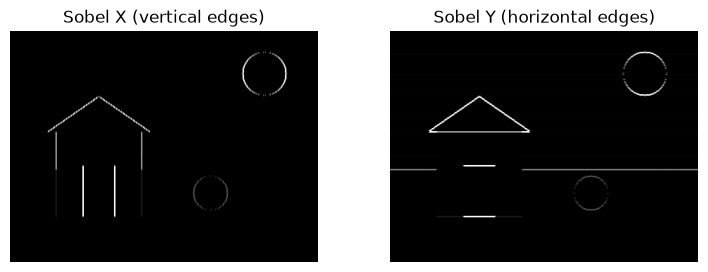

In [2]:
gray = cv2.cvtColor(cv2.imread("../assets/test_image.png"), cv2.COLOR_BGR2GRAY)
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(cv2.convertScaleAbs(sobel_x), cmap="gray"); axes[0].set_title("Sobel X (vertical edges)")
axes[1].imshow(cv2.convertScaleAbs(sobel_y), cmap="gray"); axes[1].set_title("Sobel Y (horizontal edges)")
for ax in axes: ax.axis("off")
plt.show()

## Combining gradients: magnitude and direction

The true edge strength is the magnitude sqrt(gx^2 + gy^2); the direction atan2(gy, gx) tells the edge orientation. `cv2.magnitude` and `cv2.phase` compute both. Direction is what lets Canny thin edges and link them intelligently.

Max gradient magnitude: 348.8
Mean direction at strong edges: 192.0 degrees


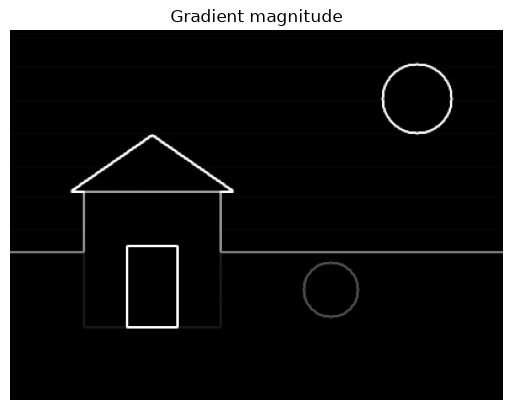

In [3]:
magnitude = cv2.magnitude(sobel_x, sobel_y)
direction = cv2.phase(sobel_x, sobel_y, angleInDegrees=True)
print("Max gradient magnitude:", round(float(magnitude.max()), 1))
print("Mean direction at strong edges:", round(float(direction[magnitude > 100].mean()), 1), "degrees")
show(cv2.convertScaleAbs(magnitude), "Gradient magnitude")

## Scharr and Laplacian

Scharr is a more accurate 3x3 gradient than Sobel. The Laplacian is a second-derivative operator: it responds to edges in all directions at once and crosses zero exactly at the edge - useful and noise-sensitive, so blur first.

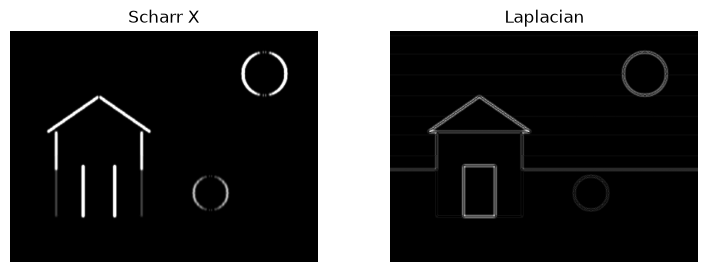

In [4]:
blur = cv2.GaussianBlur(gray, (5, 5), 0)
scharr_x = cv2.Scharr(blur, cv2.CV_64F, 1, 0)
laplacian = cv2.Laplacian(blur, cv2.CV_64F)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(cv2.convertScaleAbs(scharr_x), cmap="gray"); axes[0].set_title("Scharr X")
axes[1].imshow(cv2.convertScaleAbs(laplacian), cmap="gray"); axes[1].set_title("Laplacian")
for ax in axes: ax.axis("off")
plt.show()

## Canny edge detection

Canny = Gaussian blur -> gradients -> non-maximum suppression (thin to 1-pixel lines) -> double threshold with hysteresis (strong edges kept, weak edges kept only if connected to strong ones). The two thresholds are its main tuning knobs: start around a 1:2 or 1:3 ratio.

Edge pixels: 1086


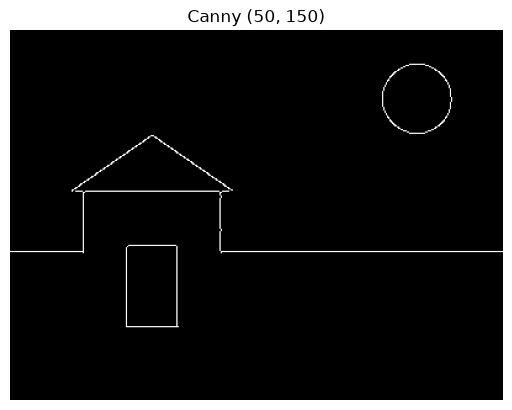

In [5]:
edges = cv2.Canny(gray, 50, 150)
print("Edge pixels:", int((edges > 0).sum()))
show(edges, "Canny (50, 150)")

## Tuning Canny thresholds

Low thresholds keep noise and texture; high thresholds lose real edges. Comparing a few pairs on your own images is the only reliable way to tune. Blurring before Canny (its internal blur is fixed) also changes results a lot on noisy images.

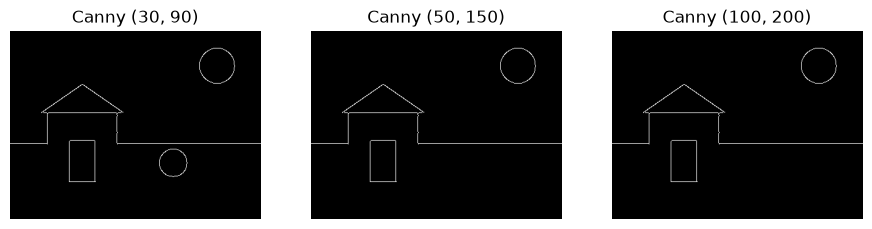

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, (lo, hi) in zip(axes, ((30, 90), (50, 150), (100, 200))):
    e = cv2.Canny(gray, lo, hi)
    ax.imshow(e, cmap="gray"); ax.set_title(f"Canny ({lo}, {hi})"); ax.axis("off")
plt.show()

## Edges as a pipeline step

Edges feed contours (notebook 11), line detection (notebook 12) and document scanning (notebook 17). A typical robust chain is: grayscale -> Gaussian blur -> Canny -> dilate slightly to close gaps -> find contours.

Edge pixels after closing gaps: 3463


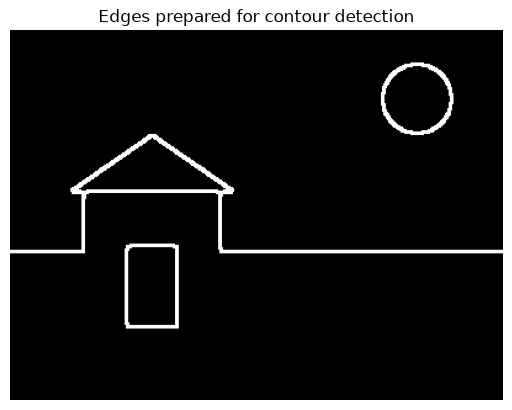

In [7]:
chain = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), 50, 150)
chain = cv2.dilate(chain, np.ones((3, 3), np.uint8), iterations=1)
print("Edge pixels after closing gaps:", int((chain > 0).sum()))
show(chain, "Edges prepared for contour detection")

## Key Points

- Sobel gives x and y derivatives; compute in CV_64F then convertScaleAbs.
- Edge strength = gradient magnitude; direction comes from atan2(gy, gx).
- Laplacian is a second-derivative, all-direction edge operator - blur first.
- Canny = blur, gradients, thinning, double threshold with hysteresis.
- Canny thresholds around a 1:2 to 1:3 ratio are a good starting point.

## Mini Task

1. Run Canny on `contours_shapes.png` and count edge pixels for thresholds (30, 90) and (100, 200).
2. Compute Sobel X on `shapes.png` grayscale and display it.
3. Explain hysteresis in your own words in a markdown cell.